# ATLAS Z Boson Reconstruction

## A Reproducible Dimuon Resonance Analysis Using ATLAS Open Data

This notebook reconstructs the Z-boson resonance in the dimuon channel
using educational ATLAS Open Data.

The analysis includes:
- ROOT dataset inspection
- Muon selection
- Opposite-charge dimuon pair construction
- Invariant-mass reconstruction
- Gaussian signal and quadratic background fitting
- Fit-window and selection robustness studies
- Residual and pull diagnostics

**Dataset:** ATLAS Open Data, Record 15003  
**Collision energy:** 13 TeV  
**Analysis channel:** Z → μ⁺μ⁻

In [3]:
%pip install uproot awkward numpy pandas matplotlib scipy

In [4]:
import uproot
import awkward as ak
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("All libraries installed successfully!")

All libraries installed successfully!


In [5]:
!wget -c -O data_A.2lep.root "https://opendata.cern.ch/record/15003/files/data_A.2lep.root"

--2026-11-26 00:57:23--  https://opendata.cern.ch/record/15003/files/data_A.2lep.root
Resolving opendata.cern.ch (opendata.cern.ch)... 137.138.6.31, 2001:1458:201:8b::100:1c8
Connecting to opendata.cern.ch (opendata.cern.ch)|137.138.6.31|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 130088359 (124M) [application/octet-stream]
Saving to: ‘data_A.2lep.root’

data_A.2lep.root    100%[===================>] 124.06M   647KB/s    in 3m 36s  

2026-11-26 01:01:00 (589 KB/s) - ‘data_A.2lep.root’ saved [130088359/130088359]



In [6]:
import os

file_path = "data_A.2lep.root"

print("File downloaded:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / (1024**2), 2), "MB")

File downloaded: True
File size: 124.06 MB


In [7]:
import uproot

root_file = uproot.open("data_A.2lep.root")

print(root_file.keys())

['mini;1']


Inspect the tree

In [8]:
tree = root_file["mini"]

print("Number of events:", tree.num_entries)
print("\nAvailable branches:")
print(tree.keys())

Number of events: 668152

Available branches:
['runNumber', 'eventNumber', 'channelNumber', 'mcWeight', 'scaleFactor_PILEUP', 'scaleFactor_ELE', 'scaleFactor_MUON', 'scaleFactor_PHOTON', 'scaleFactor_TAU', 'scaleFactor_BTAG', 'scaleFactor_LepTRIGGER', 'scaleFactor_PhotonTRIGGER', 'trigE', 'trigM', 'trigP', 'lep_n', 'lep_truthMatched', 'lep_trigMatched', 'lep_pt', 'lep_eta', 'lep_phi', 'lep_E', 'lep_z0', 'lep_charge', 'lep_type', 'lep_isTightID', 'lep_ptcone30', 'lep_etcone20', 'lep_trackd0pvunbiased', 'lep_tracksigd0pvunbiased', 'met_et', 'met_phi', 'jet_n', 'jet_pt', 'jet_eta', 'jet_phi', 'jet_E', 'jet_jvt', 'jet_trueflav', 'jet_truthMatched', 'jet_MV2c10', 'photon_n', 'photon_truthMatched', 'photon_trigMatched', 'photon_pt', 'photon_eta', 'photon_phi', 'photon_E', 'photon_isTightID', 'photon_ptcone30', 'photon_etcone20', 'photon_convType', 'tau_n', 'tau_pt', 'tau_eta', 'tau_phi', 'tau_E', 'tau_isTightID', 'tau_truthMatched', 'tau_trigMatched', 'tau_nTracks', 'tau_BDTid', 'ditau_m', '

Display branch details

In [9]:
tree.show()

name                 | typename                 | interpretation                
---------------------+--------------------------+-------------------------------
runNumber            | int32_t                  | AsDtype('>i4')
eventNumber          | int32_t                  | AsDtype('>i4')
channelNumber        | int32_t                  | AsDtype('>i4')
mcWeight             | float                    | AsDtype('>f4')
scaleFactor_PILEUP   | float                    | AsDtype('>f4')
scaleFactor_ELE      | float                    | AsDtype('>f4')
scaleFactor_MUON     | float                    | AsDtype('>f4')
scaleFactor_PHOTON   | float                    | AsDtype('>f4')
scaleFactor_TAU      | float                    | AsDtype('>f4')
scaleFactor_BTAG     | float                    | AsDtype('>f4')
scaleFactor_LepTR... | float                    | AsDtype('>f4')
scaleFactor_Photo... | float                    | AsDtype('>f4')
trigE                | bool                     | AsDtype(

Understanding the lepton data

In [10]:
import awkward as ak
import numpy as np

branches = [
    "lep_n",
    "lep_pt",
    "lep_eta",
    "lep_phi",
    "lep_E",
    "lep_charge",
    "lep_type",
    "lep_isTightID",
    "trigM"
]

sample = tree.arrays(branches, entry_stop=5, library="ak")

for branch in branches:
    print(f"\n{branch}:")
    print(sample[branch])


lep_n:
[2, 2, 2, 2, 2]

lep_pt:
[[3.31e+04, 2.11e+04], [4.29e+04, 3.72e+04], ..., [...], [4.95e+04, 3.58e+04]]

lep_eta:
[[2.18, -0.139], [0.0671, -0.946], [...], [1.95, 2.09], [-1.32, -0.482]]

lep_phi:
[[0.214, -2.67], [-0.133, -2.93], [2.46, ...], [-1.35, 1.91], [1.62, -1.4]]

lep_E:
[[1.48e+05, 2.13e+04], [4.3e+04, 5.51e+04], ..., [...], [9.91e+04, 4.01e+04]]

lep_charge:
[[-1, 1], [1, -1], [1, -1], [1, -1], [-1, 1]]

lep_type:
[[11, 11], [11, 11], [11, 11], [11, 11], [11, 11]]

lep_isTightID:
[[True, True], [True, True], [True, True], [True, True], [True, True]]

trigM:
[False, False, False, False, False]


Checking how many muons and triggers are in the dataset

In [11]:
import awkward as ak
import numpy as np

data = tree.arrays(
    ["lep_type", "lep_charge", "lep_pt", "lep_eta",
     "lep_phi", "lep_E", "lep_isTightID", "trigM"],
    library="ak"
)

# Count particle types across all leptons
all_types = ak.to_numpy(ak.flatten(data["lep_type"]))

unique_types, counts = np.unique(all_types, return_counts=True)

print("Lepton types:")
for particle_type, count in zip(unique_types, counts):
    print(f"Type {particle_type}: {count}")

# Count events with at least one muon
muon_mask = abs(data["lep_type"]) == 13
muons_per_event = ak.sum(muon_mask, axis=1)

print("\nEvents containing at least one muon:",
      int(ak.sum(muons_per_event >= 1)))

print("Events containing at least two muons:",
      int(ak.sum(muons_per_event >= 2)))

print("Events where muon trigger fired:",
      int(ak.sum(data["trigM"])))

Lepton types:
Type 11: 684503
Type 13: 655379

Events containing at least one muon: 346677
Events containing at least two muons: 308144
Events where muon trigger fired: 325321


Selecting opposite charge muon pairs

In [12]:

import uproot
import awkward as ak
import numpy as np

# Load the required branches
data = tree.arrays(
    [
        "lep_pt", "lep_eta", "lep_phi", "lep_E",
        "lep_charge", "lep_type", "lep_isTightID",
        "trigM"
    ],
    library="ak"
)

# Build a jagged collection of leptons for each event
leptons = ak.zip({
    "pt": data["lep_pt"],
    "eta": data["lep_eta"],
    "phi": data["lep_phi"],
    "E": data["lep_E"],
    "charge": data["lep_charge"],
    "type": data["lep_type"],
    "tight": data["lep_isTightID"]
})

# Select muons passing basic quality and kinematic requirements
muon_mask = (
    (leptons.type == 13) &
    (leptons.tight == True) &
    (leptons.pt > 25000) &
    (abs(leptons.eta) < 2.5)
)

muons = leptons[muon_mask]

# Require the muon trigger at event level
muons = muons[data["trigM"]]

# Form all possible pairs within each event
pairs = ak.combinations(
    muons, 2,
    fields=["mu1", "mu2"]
)

# Keep opposite-charge pairs
opposite_charge = pairs[
    pairs.mu1.charge * pairs.mu2.charge < 0
]

print("Events with selected muons:", len(muons))
print("Opposite-charge muon pairs:", len(opposite_charge))


Events with selected muons: 325321
Opposite-charge muon pairs: 325321


Correcting event and pair counts

In [13]:

# Number of selected muons in each event
muons_per_event = ak.num(muons, axis=1)

# Number of opposite-charge pairs in each event
pairs_per_event = ak.num(opposite_charge, axis=1)

print("Events after trigger:", len(muons))

print(
    "Events with >= 1 selected muon:",
    int(ak.sum(muons_per_event >= 1))
)

print(
    "Events with >= 2 selected muons:",
    int(ak.sum(muons_per_event >= 2))
)

print(
    "Total selected muons:",
    int(ak.sum(muons_per_event))
)

print(
    "Events with >= 1 opposite-charge pair:",
    int(ak.sum(pairs_per_event >= 1))
)

print(
    "Total opposite-charge pairs:",
    int(ak.sum(pairs_per_event))
)


Events after trigger: 325321
Events with >= 1 selected muon: 0
Events with >= 2 selected muons: 0
Total selected muons: 0
Events with >= 1 opposite-charge pair: 0
Total opposite-charge pairs: 0


Debug the selection one condition at a time

In [14]:

# Count objects in a jagged array
def count_objects(array):
    return int(ak.sum(ak.num(array, axis=1)))

# Start with all leptons
print("Total leptons:", count_objects(data["lep_type"]))

# 1. Muon identity
mask_type = data["lep_type"] == 13
print("Muon objects (type 13):", count_objects(data["lep_type"][mask_type]))

# 2. Tight identification
mask_tight = data["lep_isTightID"] == True
mask_type_tight = mask_type & mask_tight
print("Muons passing tight ID:", count_objects(data["lep_type"][mask_type_tight]))

# 3. Transverse momentum
mask_pt = data["lep_pt"] > 25000
mask_type_tight_pt = mask_type_tight & mask_pt
print("Muons passing pT:", count_objects(data["lep_type"][mask_type_tight_pt]))

# 4. Pseudorapidity
mask_eta = abs(data["lep_eta"]) < 2.5
mask_all = mask_type_tight_pt & mask_eta
print("Muons passing all cuts:", count_objects(data["lep_type"][mask_all]))

# 5. Trigger
mask_trigger = data["trigM"]
mask_all_trigger = mask_all & mask_trigger
print("Muons passing cuts + trigger:", count_objects(data["lep_type"][mask_all_trigger]))


Total leptons: 1339882
Muon objects (type 13): 655379
Muons passing tight ID: 605132
Muons passing pT: 549847
Muons passing all cuts: 549847
Muons passing cuts + trigger: 548403


Corrected muon selection

In [15]:

# Build the selection mask directly from the original branches
selection_mask = (
    (data["lep_type"] == 13) &
    (data["lep_isTightID"] == True) &
    (data["lep_pt"] > 25000) &
    (abs(data["lep_eta"]) < 2.5)
)

# Create a lepton record and select the muons
selected_muons = ak.zip({
    "pt": data["lep_pt"],
    "eta": data["lep_eta"],
    "phi": data["lep_phi"],
    "E": data["lep_E"],
    "charge": data["lep_charge"]
})

selected_muons = selected_muons[selection_mask]

# Apply the event-level muon trigger
selected_muons = selected_muons[data["trigM"]]

# Form pairs of selected muons in each event
pairs = ak.combinations(
    selected_muons,
    2,
    fields=["mu1", "mu2"]
)

# Keep opposite-charge pairs
opposite_charge = pairs[
    pairs["mu1"]["charge"] * pairs["mu2"]["charge"] < 0
]

# Correctly count events and pairs
muons_per_event = ak.num(selected_muons, axis=1)
pairs_per_event = ak.num(opposite_charge, axis=1)

print("Events after trigger:", len(selected_muons))
print("Events with >= 1 selected muon:",
      int(ak.sum(muons_per_event >= 1)))
print("Events with >= 2 selected muons:",
      int(ak.sum(muons_per_event >= 2)))
print("Total selected muons:",
      int(ak.sum(muons_per_event)))
print("Events with opposite-charge pair:",
      int(ak.sum(pairs_per_event >= 1)))
print("Total opposite-charge pairs:",
      int(ak.sum(pairs_per_event)))


Events after trigger: 325321
Events with >= 1 selected muon: 321876
Events with >= 2 selected muons: 226508
Total selected muons: 548403
Events with opposite-charge pair: 226463
Total opposite-charge pairs: 226483


Calculating the invariant mass

In [16]:

# Extract the two muons from every opposite-charge pair
mu1 = opposite_charge["mu1"]
mu2 = opposite_charge["mu2"]

# Convert transverse momentum from MeV to GeV
pt1 = mu1["pt"] / 1000.0
pt2 = mu2["pt"] / 1000.0

# Energy from MeV to GeV
E1 = mu1["E"] / 1000.0
E2 = mu2["E"] / 1000.0

# Momentum components in GeV
px1 = pt1 * np.cos(mu1["phi"])
py1 = pt1 * np.sin(mu1["phi"])
pz1 = pt1 * np.sinh(mu1["eta"])

px2 = pt2 * np.cos(mu2["phi"])
py2 = pt2 * np.sin(mu2["phi"])
pz2 = pt2 * np.sinh(mu2["eta"])

# Invariant mass squared
mass_squared = (
    (E1 + E2)**2
    - (px1 + px2)**2
    - (py1 + py2)**2
    - (pz1 + pz2)**2
)

# Protect against tiny negative values from floating-point precision
invariant_mass = np.sqrt(ak.where(mass_squared > 0, mass_squared, 0))

# Flatten event-wise pairs into a one-dimensional array
mass_values = ak.to_numpy(ak.flatten(invariant_mass))

print("Number of reconstructed pairs:", len(mass_values))
print("Minimum mass (GeV):", np.min(mass_values))
print("Maximum mass (GeV):", np.max(mass_values))
print("Mean mass (GeV):", np.mean(mass_values))


Number of reconstructed pairs: 226483
Minimum mass (GeV): 0.508232998977831
Maximum mass (GeV): 933.4438587831621
Mean mass (GeV): 90.97624456643992


Plotting the mass distribution

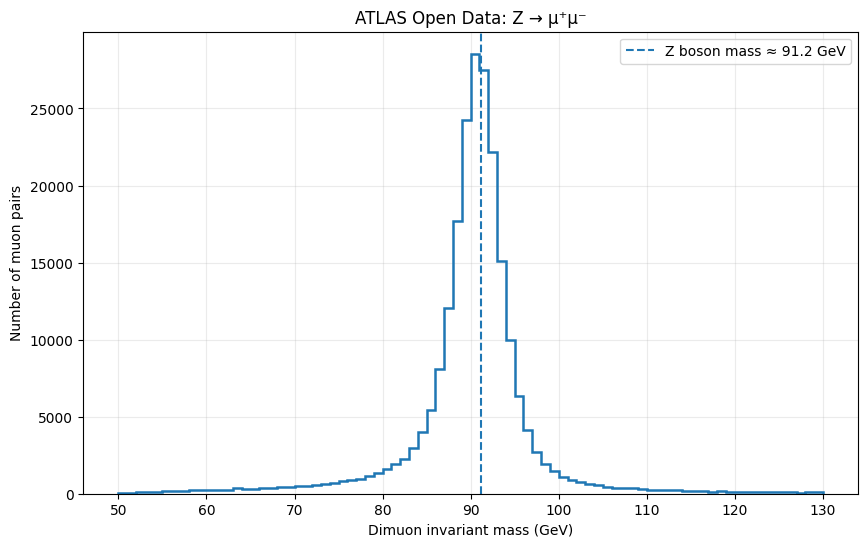

In [17]:

plt.figure(figsize=(10, 6))

plt.hist(
    mass_values,
    bins=80,
    range=(50, 130),
    histtype="step",
    linewidth=1.8
)

plt.axvline(
    91.2,
    linestyle="--",
    label="Z boson mass ≈ 91.2 GeV"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Number of muon pairs")
plt.title("ATLAS Open Data: Z → μ⁺μ⁻")
plt.legend()
plt.grid(alpha=0.25)

plt.show()


Finding the Z boson peak

In [18]:

# Focus on the Z boson mass region
z_region = mass_values[
    (mass_values >= 70) &
    (mass_values <= 110)
]

# Find the most populated histogram bin
hist_counts, hist_edges = np.histogram(
    z_region,
    bins=80,
    range=(70, 110)
)

peak_bin = np.argmax(hist_counts)

peak_mass = (
    hist_edges[peak_bin] + hist_edges[peak_bin + 1]
) / 2

print("Pairs in 70–110 GeV region:", len(z_region))
print("Histogram peak estimate:", peak_mass, "GeV")
print("Peak-bin count:", hist_counts[peak_bin])


Pairs in 70–110 GeV region: 213994
Histogram peak estimate: 90.75 GeV
Peak-bin count: 14527


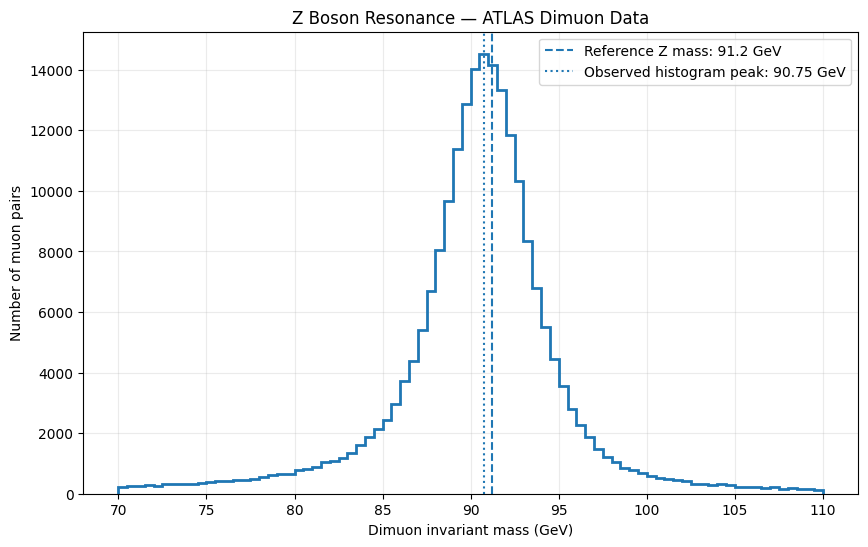

In [19]:

plt.figure(figsize=(10, 6))

plt.hist(
    z_region,
    bins=80,
    range=(70, 110),
    histtype="step",
    linewidth=2
)

plt.axvline(
    91.2,
    linestyle="--",
    label="Reference Z mass: 91.2 GeV"
)

plt.axvline(
    peak_mass,
    linestyle=":",
    label=f"Observed histogram peak: {peak_mass:.2f} GeV"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Number of muon pairs")
plt.title("Z Boson Resonance — ATLAS Dimuon Data")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


Fitting the Z Boson resonance

In [20]:

from scipy.optimize import curve_fit

# Fit in a focused resonance window
fit_min = 80
fit_max = 100
bins = 80

counts, edges = np.histogram(
    mass_values,
    bins=bins,
    range=(fit_min, fit_max)
)

centers = (edges[:-1] + edges[1:]) / 2

# Gaussian signal + linear background
def gaussian_background(x, amplitude, mean, sigma, intercept, slope):
    gaussian = amplitude * np.exp(
        -0.5 * ((x - mean) / sigma)**2
    )
    background = intercept + slope * x
    return gaussian + background

# Initial parameter guesses
initial_guess = [
    counts.max(),
    91.0,
    2.0,
    np.median(counts),
    0.0
]

# Fit the histogram
fit_params, covariance = curve_fit(
    gaussian_background,
    centers,
    counts,
    p0=initial_guess,
    bounds=(
        [0, 85, 0.2, -np.inf, -np.inf],
        [np.inf, 97, 8, np.inf, np.inf]
    ),
    maxfev=20000
)

amplitude, fitted_mass, fitted_sigma, intercept, slope = fit_params

# Approximate parameter uncertainty from covariance matrix
mass_uncertainty = np.sqrt(covariance[1, 1])

print(f"Fitted Z mass: {fitted_mass:.3f} GeV")
print(f"Fit statistical uncertainty: ±{mass_uncertainty:.3f} GeV")
print(f"Fitted Gaussian width: {fitted_sigma:.3f} GeV")


Fitted Z mass: 90.806 GeV
Fit statistical uncertainty: ±0.021 GeV
Fitted Gaussian width: 2.384 GeV


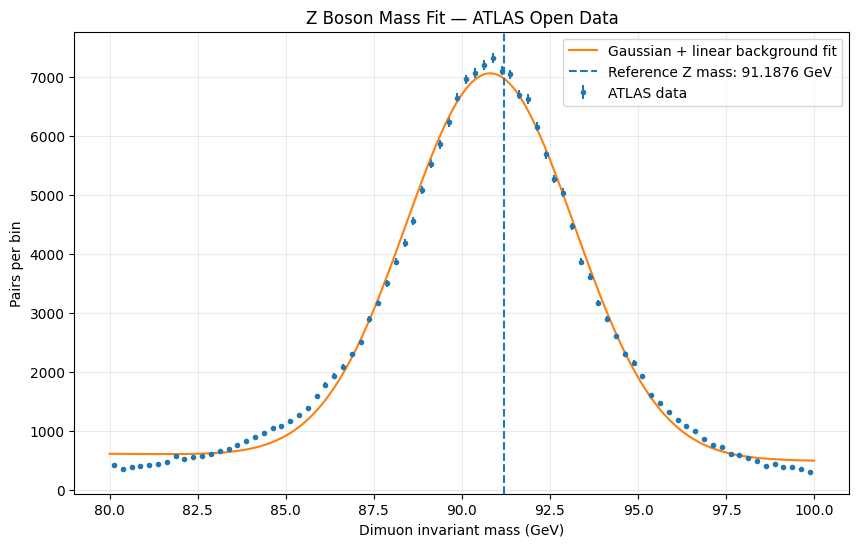

In [21]:

x_fit = np.linspace(fit_min, fit_max, 500)
y_fit = gaussian_background(x_fit, *fit_params)

plt.figure(figsize=(10, 6))

plt.errorbar(
    centers,
    counts,
    yerr=np.sqrt(np.maximum(counts, 1)),
    fmt="o",
    markersize=3,
    label="ATLAS data"
)

plt.plot(
    x_fit,
    y_fit,
    label="Gaussian + linear background fit"
)

plt.axvline(
    91.1876,
    linestyle="--",
    label="Reference Z mass: 91.1876 GeV"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Pairs per bin")
plt.title("Z Boson Mass Fit — ATLAS Open Data")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


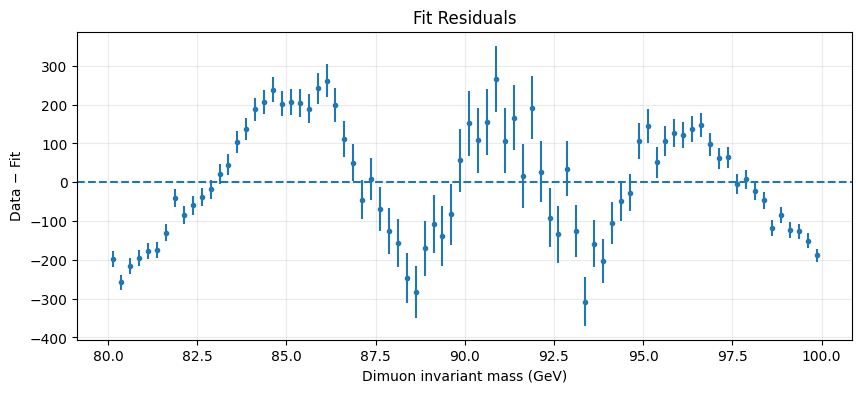

In [22]:

predicted_counts = gaussian_background(centers, *fit_params)

residuals = counts - predicted_counts

plt.figure(figsize=(10, 4))

plt.axhline(0, linestyle="--")
plt.errorbar(
    centers,
    residuals,
    yerr=np.sqrt(np.maximum(counts, 1)),
    fmt="o",
    markersize=3
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Data − Fit")
plt.title("Fit Residuals")
plt.grid(alpha=0.25)
plt.show()


In [23]:

muon_mass = 0.10566  # GeV

# Muon energies reconstructed from momentum and rest mass
p1_squared = px1**2 + py1**2 + pz1**2
p2_squared = px2**2 + py2**2 + pz2**2

E1_check = np.sqrt(p1_squared + muon_mass**2)
E2_check = np.sqrt(p2_squared + muon_mass**2)

mass_squared_check = (
    (E1_check + E2_check)**2
    - (px1 + px2)**2
    - (py1 + py2)**2
    - (pz1 + pz2)**2
)

mass_check = np.sqrt(
    ak.where(mass_squared_check > 0, mass_squared_check, 0)
)

mass_check_values = ak.to_numpy(ak.flatten(mass_check))

print("Original mean mass:", np.mean(mass_values), "GeV")
print("Cross-check mean mass:", np.mean(mass_check_values), "GeV")
print(
    "Mean absolute difference:",
    np.mean(np.abs(mass_values - mass_check_values)),
    "GeV"
)


Original mean mass: 90.97624456643992 GeV
Cross-check mean mass: 90.9762446119796 GeV
Mean absolute difference: 1.9958379796952586e-05 GeV


In [24]:
# ============================================================
# STEP 1: EVENT-LEVEL CUTFLOW
# ============================================================

# Total number of events
total_events = len(data)

# Event-level muon trigger
trigger_mask = data["trigM"]

# Muon object selection
muon_mask = (
    (data["lep_type"] == 13) &
    (data["lep_isTightID"] == True) &
    (data["lep_pt"] > 25000) &
    (abs(data["lep_eta"]) < 2.5)
)

# Number of selected muons in each event
selected_muons_per_event = ak.sum(muon_mask, axis=1)

# Event-level selection stages
events_after_trigger = trigger_mask

events_at_least_one_muon = (
    trigger_mask &
    (selected_muons_per_event >= 1)
)

events_at_least_two_muons = (
    trigger_mask &
    (selected_muons_per_event >= 2)
)

events_exactly_two_muons = (
    trigger_mask &
    (selected_muons_per_event == 2)
)

# Create the cutflow table
cut_names = [
    "All events",
    "Muon trigger",
    "At least 1 selected muon",
    "At least 2 selected muons",
    "Exactly 2 selected muons"
]

cut_counts = [
    total_events,
    int(ak.sum(events_after_trigger)),
    int(ak.sum(events_at_least_one_muon)),
    int(ak.sum(events_at_least_two_muons)),
    int(ak.sum(events_exactly_two_muons))
]

cutflow = pd.DataFrame({
    "Selection": cut_names,
    "Events": cut_counts
})

cutflow["Efficiency (%)"] = (
    cutflow["Events"] / total_events * 100
)

cutflow["Step efficiency (%)"] = (
    cutflow["Events"] /
    cutflow["Events"].shift(1) * 100
)

cutflow.loc[0, "Step efficiency (%)"] = 100

print("EVENT-LEVEL CUTFLOW")
display(cutflow)

EVENT-LEVEL CUTFLOW


,Selection,Events,Efficiency (%),Step efficiency (%)
0,All events,668152,100.000000,100.000000
1,Muon trigger,325321,48.689669,48.689669
2,At least 1 selected muon,321876,48.174068,98.941046
3,At least 2 selected muons,226508,33.900669,70.371199
4,Exactly 2 selected muons,226490,33.897975,99.992053


INCLUSIVE PAIR SAMPLE
Events with at least one opposite-charge pair: 226463
Total opposite-charge pairs: 226483

EXACTLY TWO SELECTED MUONS
Events with exactly two selected muons: 226490
Opposite-charge pairs: 226445

Mass entries in inclusive sample: 226483
Mass entries in exactly-two sample: 226445
Inclusive sample mean mass: 90.97624456643992 GeV
Exactly-two sample mean mass: 90.97344603027162 GeV


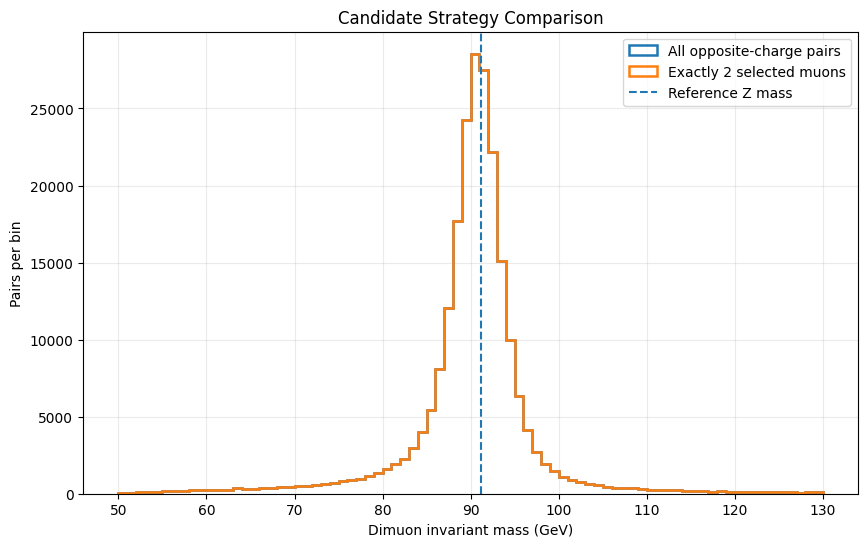

In [25]:
# ============================================================
# STEP 2: COMPARE DIMUON CANDIDATE STRATEGIES
# ============================================================

# Number of selected muons in each event
muons_per_event = ak.num(selected_muons, axis=1)

# Select events containing exactly two selected muons
exactly_two_mask = muons_per_event == 2

selected_muons_exactly_two = selected_muons[exactly_two_mask]

# Construct pairs for the exactly-two-muon sample
pairs_exactly_two = ak.combinations(
    selected_muons_exactly_two,
    2,
    fields=["mu1", "mu2"]
)

# Keep opposite-charge pairs
opposite_charge_exactly_two = pairs_exactly_two[
    pairs_exactly_two["mu1"]["charge"] *
    pairs_exactly_two["mu2"]["charge"] < 0
]

print("INCLUSIVE PAIR SAMPLE")
print("Events with at least one opposite-charge pair:",
      int(ak.sum(ak.num(opposite_charge, axis=1) >= 1)))
print("Total opposite-charge pairs:",
      int(ak.sum(ak.num(opposite_charge, axis=1))))

print("\nEXACTLY TWO SELECTED MUONS")
print("Events with exactly two selected muons:",
      len(selected_muons_exactly_two))
print("Opposite-charge pairs:",
      int(ak.sum(ak.num(opposite_charge_exactly_two, axis=1))))

# ------------------------------------------------------------
# Reconstruct invariant mass for exactly-two-muon pairs
# ------------------------------------------------------------

mu1_exact = opposite_charge_exactly_two["mu1"]
mu2_exact = opposite_charge_exactly_two["mu2"]

pt1_exact = mu1_exact["pt"] / 1000.0
pt2_exact = mu2_exact["pt"] / 1000.0

E1_exact = mu1_exact["E"] / 1000.0
E2_exact = mu2_exact["E"] / 1000.0

px1_exact = pt1_exact * np.cos(mu1_exact["phi"])
py1_exact = pt1_exact * np.sin(mu1_exact["phi"])
pz1_exact = pt1_exact * np.sinh(mu1_exact["eta"])

px2_exact = pt2_exact * np.cos(mu2_exact["phi"])
py2_exact = pt2_exact * np.sin(mu2_exact["phi"])
pz2_exact = pt2_exact * np.sinh(mu2_exact["eta"])

mass_squared_exact = (
    (E1_exact + E2_exact)**2
    - (px1_exact + px2_exact)**2
    - (py1_exact + py2_exact)**2
    - (pz1_exact + pz2_exact)**2
)

mass_exact = np.sqrt(
    ak.where(mass_squared_exact > 0, mass_squared_exact, 0)
)

mass_exact_values = ak.to_numpy(
    ak.flatten(mass_exact)
)

print("\nMass entries in inclusive sample:", len(mass_values))
print("Mass entries in exactly-two sample:", len(mass_exact_values))

print("Inclusive sample mean mass:",
      np.mean(mass_values), "GeV")

print("Exactly-two sample mean mass:",
      np.mean(mass_exact_values), "GeV")

# ------------------------------------------------------------
# Compare the two mass distributions
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    mass_values,
    bins=80,
    range=(50, 130),
    histtype="step",
    linewidth=1.8,
    label="All opposite-charge pairs"
)

plt.hist(
    mass_exact_values,
    bins=80,
    range=(50, 130),
    histtype="step",
    linewidth=1.8,
    label="Exactly 2 selected muons"
)

plt.axvline(
    91.1876,
    linestyle="--",
    label="Reference Z mass"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Pairs per bin")
plt.title("Candidate Strategy Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


Inclusive opposite-charge pairs
---------------------------------------------
Fitted peak: 90.7789 GeV
Approx. fit uncertainty: ±0.0078 GeV
Gaussian width: 2.5472 GeV
Chi-square: 1089.88
Degrees of freedom: 75
Reduced chi-square: 14.532

Exactly two selected muons
---------------------------------------------
Fitted peak: 90.7789 GeV
Approx. fit uncertainty: ±0.0078 GeV
Gaussian width: 2.5473 GeV
Chi-square: 1089.68
Degrees of freedom: 75
Reduced chi-square: 14.529

COMPARISON
---------------------------------------------
Difference in fitted peaks: -0.0000 GeV


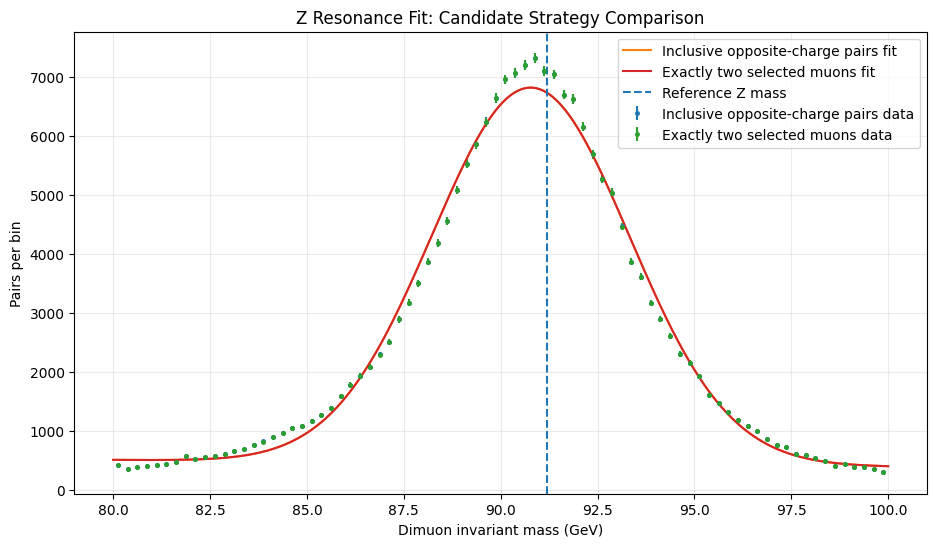

In [26]:
# ============================================================
# STEP 3: WEIGHTED RESONANCE FIT AND FIT-QUALITY CHECK
# ============================================================

from scipy.optimize import curve_fit

fit_min = 80
fit_max = 100
number_of_bins = 80

def gaussian_linear_background(
    x, amplitude, mean, sigma, intercept, slope
):
    signal = amplitude * np.exp(
        -0.5 * ((x - mean) / sigma)**2
    )
    background = intercept + slope * x
    return signal + background


def fit_resonance(masses, sample_name):

    # Histogram in the same fit range for both samples
    counts, edges = np.histogram(
        masses,
        bins=number_of_bins,
        range=(fit_min, fit_max)
    )

    centers = (edges[:-1] + edges[1:]) / 2

    # Approximate Poisson uncertainties for histogram counts
    errors = np.sqrt(np.maximum(counts, 1))

    initial_guess = [
        max(counts.max() - np.median(counts), 1),
        91.0,
        2.5,
        np.median(counts),
        0.0
    ]

    parameters, covariance = curve_fit(
        gaussian_linear_background,
        centers,
        counts,
        p0=initial_guess,
        sigma=errors,
        absolute_sigma=True,
        bounds=(
            [0, 85, 0.2, -np.inf, -np.inf],
            [np.inf, 97, 8, np.inf, np.inf]
        ),
        maxfev=30000
    )

    amplitude, mean, sigma, intercept, slope = parameters

    parameter_errors = np.sqrt(
        np.diag(covariance)
    )

    # Calculate chi-square using the fitted model
    expected = gaussian_linear_background(
        centers, *parameters
    )

    chi_square = np.sum(
        ((counts - expected) / errors)**2
    )

    degrees_of_freedom = len(counts) - len(parameters)

    reduced_chi_square = (
        chi_square / degrees_of_freedom
    )

    print(f"\n{sample_name}")
    print("-" * 45)
    print(f"Fitted peak: {mean:.4f} GeV")
    print(f"Approx. fit uncertainty: ±{parameter_errors[1]:.4f} GeV")
    print(f"Gaussian width: {sigma:.4f} GeV")
    print(f"Chi-square: {chi_square:.2f}")
    print(f"Degrees of freedom: {degrees_of_freedom}")
    print(f"Reduced chi-square: {reduced_chi_square:.3f}")

    return {
        "name": sample_name,
        "counts": counts,
        "centers": centers,
        "parameters": parameters,
        "covariance": covariance,
        "mean": mean,
        "mean_error": parameter_errors[1],
        "sigma": sigma,
        "chi_square": chi_square,
        "ndof": degrees_of_freedom,
        "reduced_chi_square": reduced_chi_square
    }


# Fit both candidate samples
fit_inclusive = fit_resonance(
    mass_values,
    "Inclusive opposite-charge pairs"
)

fit_exact = fit_resonance(
    mass_exact_values,
    "Exactly two selected muons"
)

# Compare fitted peak positions
peak_difference = (
    fit_inclusive["mean"] - fit_exact["mean"]
)

print("\nCOMPARISON")
print("-" * 45)
print(
    "Difference in fitted peaks:",
    f"{peak_difference:.4f} GeV"
)

# Plot both fitted distributions
x_plot = np.linspace(fit_min, fit_max, 500)

plt.figure(figsize=(11, 6))

for result in [fit_inclusive, fit_exact]:

    plt.errorbar(
        result["centers"],
        result["counts"],
        yerr=np.sqrt(np.maximum(result["counts"], 1)),
        fmt="o",
        markersize=2.5,
        label=f'{result["name"]} data'
    )

    y_plot = gaussian_linear_background(
        x_plot,
        *result["parameters"]
    )

    plt.plot(
        x_plot,
        y_plot,
        label=f'{result["name"]} fit'
    )

plt.axvline(
    91.1876,
    linestyle="--",
    label="Reference Z mass"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Pairs per bin")
plt.title("Z Resonance Fit: Candidate Strategy Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

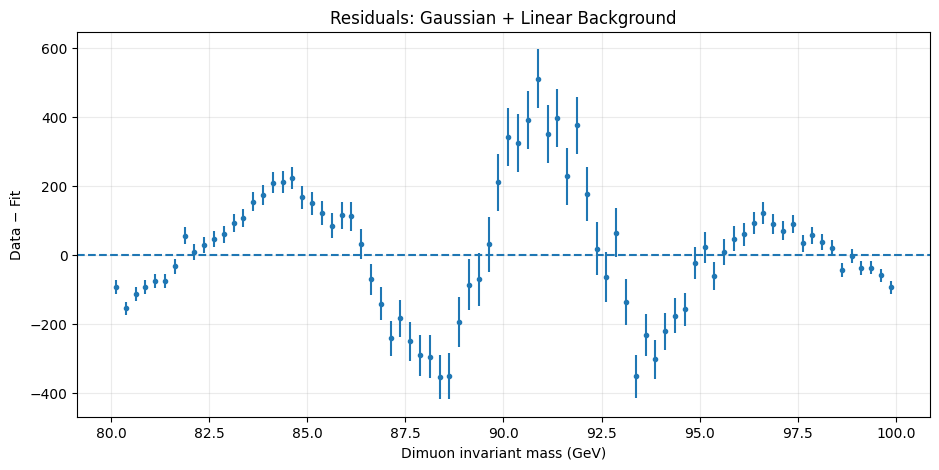

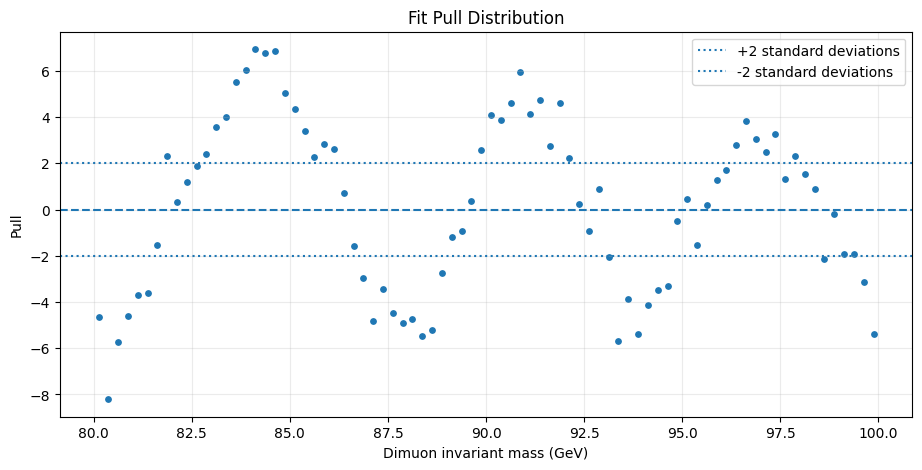

Mean pull: 0.19116623072934216
Standard deviation of pulls: 3.686048097358744
Largest absolute pull: 8.207497719696406


In [27]:
# ============================================================
# STEP 4: RESIDUALS AND PULL DISTRIBUTION
# ============================================================

result = fit_inclusive

counts = result["counts"]
centers = result["centers"]
parameters = result["parameters"]

expected_counts = gaussian_linear_background(
    centers, *parameters
)

bin_errors = np.sqrt(np.maximum(counts, 1))

residuals = counts - expected_counts

pulls = residuals / bin_errors

# Residual plot
plt.figure(figsize=(11, 5))

plt.axhline(0, linestyle="--")
plt.errorbar(
    centers,
    residuals,
    yerr=bin_errors,
    fmt="o",
    markersize=3
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Data − Fit")
plt.title("Residuals: Gaussian + Linear Background")
plt.grid(alpha=0.25)
plt.show()

# Pull plot
plt.figure(figsize=(11, 5))

plt.axhline(0, linestyle="--")
plt.axhline(2, linestyle=":", label="+2 standard deviations")
plt.axhline(-2, linestyle=":", label="-2 standard deviations")

plt.scatter(
    centers,
    pulls,
    s=15
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Pull")
plt.title("Fit Pull Distribution")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Mean pull:", np.mean(pulls))
print("Standard deviation of pulls:", np.std(pulls))
print("Largest absolute pull:", np.max(np.abs(pulls)))

In [28]:
# ============================================================
# STEP 5: FIT-WINDOW STABILITY
# ============================================================

fit_windows = [
    (80, 100),
    (85, 97),
    (75, 105)
]

stability_results = []

for lower, upper in fit_windows:

    counts_window, edges_window = np.histogram(
        mass_exact_values,
        bins=80,
        range=(lower, upper)
    )

    centers_window = (
        edges_window[:-1] + edges_window[1:]
    ) / 2

    errors_window = np.sqrt(
        np.maximum(counts_window, 1)
    )

    initial = [
        max(counts_window.max() - np.median(counts_window), 1),
        91.0,
        2.5,
        np.median(counts_window),
        0.0
    ]

    parameters_window, covariance_window = curve_fit(
        gaussian_linear_background,
        centers_window,
        counts_window,
        p0=initial,
        sigma=errors_window,
        absolute_sigma=True,
        bounds=(
            [0, 85, 0.2, -np.inf, -np.inf],
            [np.inf, 97, 8, np.inf, np.inf]
        ),
        maxfev=30000
    )

    errors_parameters = np.sqrt(
        np.diag(covariance_window)
    )

    expected_window = gaussian_linear_background(
        centers_window,
        *parameters_window
    )

    chi2_window = np.sum(
        (
            (counts_window - expected_window) /
            errors_window
        )**2
    )

    ndof_window = (
        len(counts_window) - len(parameters_window)
    )

    stability_results.append({
        "Fit range (GeV)": f"{lower}–{upper}",
        "Fitted peak (GeV)": parameters_window[1],
        "Peak uncertainty (GeV)": errors_parameters[1],
        "Gaussian width (GeV)": parameters_window[2],
        "Reduced chi-square": chi2_window / ndof_window
    })

stability_table = pd.DataFrame(stability_results)

display(stability_table)

,Fit range (GeV),Fitted peak (GeV),Peak uncertainty (GeV),Gaussian width (GeV),Reduced chi-square
0,80–100,90.778924,0.007768,2.547267,14.529117
1,85–97,90.839537,0.010330,2.217689,2.033681
2,75–105,90.759270,0.007370,2.769617,45.604728


In [29]:
fit_peaks = np.array([
    90.778924,
    90.839537,
    90.759270
])

peak_spread = fit_peaks.max() - fit_peaks.min()

print(f"Minimum fitted peak: {fit_peaks.min():.4f} GeV")
print(f"Maximum fitted peak: {fit_peaks.max():.4f} GeV")
print(f"Fit-window peak spread: {peak_spread:.4f} GeV")
print(f"Fit-window peak spread: {peak_spread * 1000:.1f} MeV")

Minimum fitted peak: 90.7593 GeV
Maximum fitted peak: 90.8395 GeV
Fit-window peak spread: 0.0803 GeV
Fit-window peak spread: 80.3 MeV



### Fit-window stability

The dimuon invariant-mass distribution was fitted using a Gaussian signal
component with a linear background over three mass intervals.

The fitted peak varied from 90.7593 to 90.8395 GeV, corresponding to a
fit-window spread of 80.3 MeV. The 85-97 GeV interval gave the lowest
reduced chi-square (approximately 2.03), while the wider intervals showed
substantially poorer goodness of fit.

This demonstrates that the fitted peak depends on the selected fit interval
and that the Gaussian-plus-linear model does not fully describe the observed
mass distribution across all tested ranges. The covariance uncertainty
from the fit is therefore not interpreted as the total uncertainty.

The result is a preliminary reconstruction using educational ATLAS Open
Data, not a precision measurement of the Z-boson mass.


GAUSSIAN + LINEAR BACKGROUND
Peak: 90.8395 GeV
Peak covariance uncertainty: 0.0103 GeV
Reduced chi-square: 2.034

GAUSSIAN + QUADRATIC BACKGROUND
Peak: 90.8295 GeV
Peak covariance uncertainty: 0.0111 GeV
Reduced chi-square: 1.132


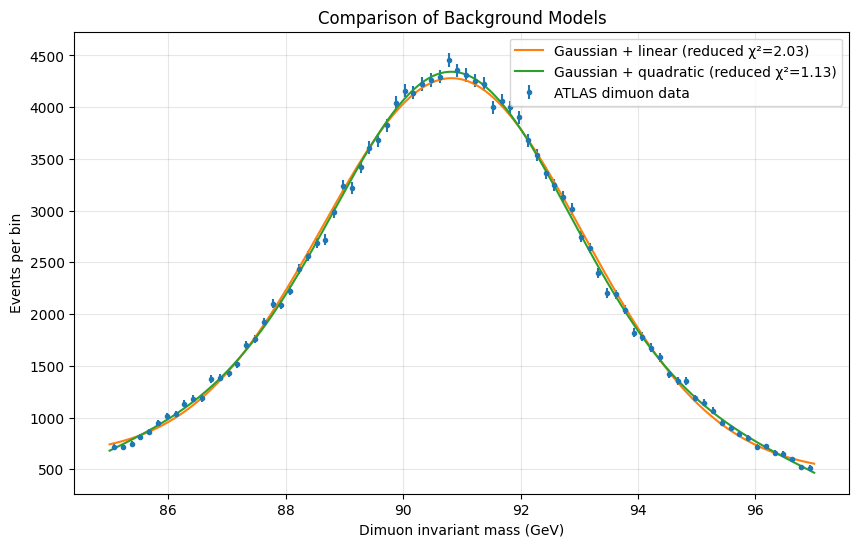

In [30]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Use exactly the same data and bins for both models
fit_low = 85
fit_high = 97
n_bins = 80

hist_counts, bin_edges = np.histogram(
    mass_exact_values,
    bins=n_bins,
    range=(fit_low, fit_high)
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Poisson-style uncertainties for histogram counts
bin_errors = np.sqrt(np.maximum(hist_counts, 1))


# Model 1: Gaussian signal + linear background
def gaussian_linear(x, A, mu, sigma, a, b):
    gaussian = A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    background = a * x + b
    return gaussian + background


# Model 2: Gaussian signal + quadratic background
def gaussian_quadratic(x, A, mu, sigma, a, b, c):
    gaussian = A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    background = a * x**2 + b * x + c
    return gaussian + background


# Initial parameter guesses
initial_linear = [
    hist_counts.max(),  # amplitude
    91.0,               # peak
    2.5,                # width
    0.0,                # linear slope
    np.median(hist_counts)
]

initial_quadratic = [
    hist_counts.max(),
    91.0,
    2.5,
    0.0,
    0.0,
    np.median(hist_counts)
]


# Fit linear-background model
params_linear, covariance_linear = curve_fit(
    gaussian_linear,
    bin_centers,
    hist_counts,
    p0=initial_linear,
    sigma=bin_errors,
    absolute_sigma=True,
    maxfev=20000
)


# Fit quadratic-background model
params_quad, covariance_quad = curve_fit(
    gaussian_quadratic,
    bin_centers,
    hist_counts,
    p0=initial_quadratic,
    sigma=bin_errors,
    absolute_sigma=True,
    maxfev=20000
)


# Calculate chi-square and reduced chi-square
def calculate_fit_statistics(model, params, n_parameters):
    expected = model(bin_centers, *params)

    chi_square = np.sum(
        ((hist_counts - expected) / bin_errors) ** 2
    )

    degrees_of_freedom = len(hist_counts) - n_parameters
    reduced_chi_square = chi_square / degrees_of_freedom

    return chi_square, degrees_of_freedom, reduced_chi_square


chi2_linear, dof_linear, redchi_linear = calculate_fit_statistics(
    gaussian_linear, params_linear, 5
)

chi2_quad, dof_quad, redchi_quad = calculate_fit_statistics(
    gaussian_quadratic, params_quad, 6
)


# Extract peak and its covariance uncertainty
peak_linear = params_linear[1]
peak_error_linear = np.sqrt(covariance_linear[1, 1])

peak_quad = params_quad[1]
peak_error_quad = np.sqrt(covariance_quad[1, 1])


print("GAUSSIAN + LINEAR BACKGROUND")
print(f"Peak: {peak_linear:.4f} GeV")
print(f"Peak covariance uncertainty: {peak_error_linear:.4f} GeV")
print(f"Reduced chi-square: {redchi_linear:.3f}")

print("\nGAUSSIAN + QUADRATIC BACKGROUND")
print(f"Peak: {peak_quad:.4f} GeV")
print(f"Peak covariance uncertainty: {peak_error_quad:.4f} GeV")
print(f"Reduced chi-square: {redchi_quad:.3f}")


# Plot both fitted models
plt.figure(figsize=(10, 6))

plt.errorbar(
    bin_centers,
    hist_counts,
    yerr=bin_errors,
    fmt="o",
    markersize=3,
    label="ATLAS dimuon data"
)

smooth_mass = np.linspace(fit_low, fit_high, 500)

plt.plot(
    smooth_mass,
    gaussian_linear(smooth_mass, *params_linear),
    label=f"Gaussian + linear (reduced χ²={redchi_linear:.2f})"
)

plt.plot(
    smooth_mass,
    gaussian_quadratic(smooth_mass, *params_quad),
    label=f"Gaussian + quadratic (reduced χ²={redchi_quad:.2f})"
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Events per bin")
plt.title("Comparison of Background Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


QUADRATIC MODEL FIT QUALITY
Chi-square: 83.78
Degrees of freedom: 74
Reduced chi-square: 1.132
Chi-square p-value: 0.205
Mean pull: 0.012
Pull standard deviation: 1.023


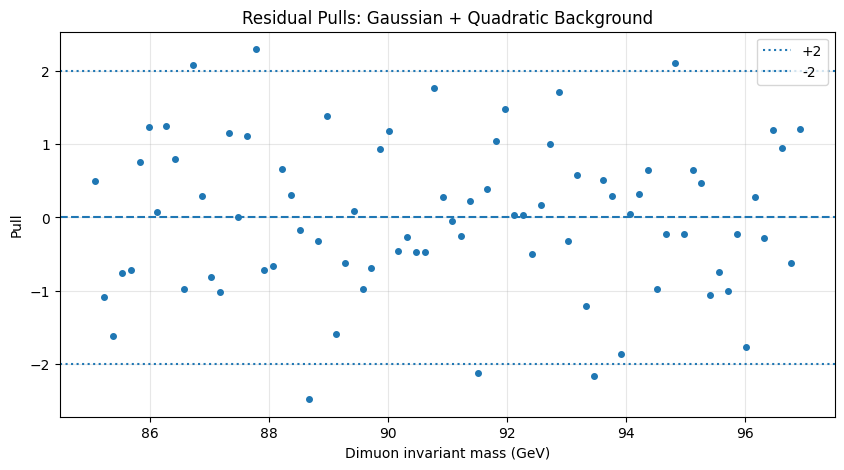

In [31]:

from scipy.stats import chi2
import matplotlib.pyplot as plt
import numpy as np

# Expected counts from the quadratic model
quadratic_expected = gaussian_quadratic(
    bin_centers, *params_quad
)

# Pulls: observed minus expected, divided by bin uncertainty
quadratic_pulls = (
    hist_counts - quadratic_expected
) / bin_errors

# Goodness-of-fit probability
chi2_quad = redchi_quad * dof_quad
p_value_quad = chi2.sf(chi2_quad, dof_quad)

print("QUADRATIC MODEL FIT QUALITY")
print(f"Chi-square: {chi2_quad:.2f}")
print(f"Degrees of freedom: {dof_quad}")
print(f"Reduced chi-square: {redchi_quad:.3f}")
print(f"Chi-square p-value: {p_value_quad:.3f}")
print(f"Mean pull: {np.mean(quadratic_pulls):.3f}")
print(f"Pull standard deviation: {np.std(quadratic_pulls):.3f}")


# Residual/pull plot
plt.figure(figsize=(10, 5))

plt.axhline(0, linestyle="--")
plt.axhline(2, linestyle=":", label="+2")
plt.axhline(-2, linestyle=":", label="-2")

plt.errorbar(
    bin_centers,
    quadratic_pulls,
    fmt="o",
    markersize=4
)

plt.xlabel("Dimuon invariant mass (GeV)")
plt.ylabel("Pull")
plt.title("Residual Pulls: Gaussian + Quadratic Background")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [32]:

import numpy as np
from scipy.optimize import curve_fit

# Fit windows to compare
fit_windows = [
    (80, 100),
    (85, 97),
    (75, 105)
]

results_quad_stability = []

# Center the polynomial around 91 GeV to improve numerical stability
def gaussian_quadratic_centered(x, A, mu, sigma, a, b, c):
    t = x - 91.0
    signal = A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    background = a * t**2 + b * t + c
    return signal + background


for low, high in fit_windows:

    counts, edges = np.histogram(
        mass_exact_values,
        bins=80,
        range=(low, high)
    )

    centers = (edges[:-1] + edges[1:]) / 2
    errors = np.sqrt(np.maximum(counts, 1))

    initial_guess = [
        counts.max(),
        91.0,
        2.5,
        0.0,
        0.0,
        np.median(counts)
    ]

    params, covariance = curve_fit(
        gaussian_quadratic_centered,
        centers,
        counts,
        p0=initial_guess,
        sigma=errors,
        absolute_sigma=True,
        maxfev=30000
    )

    expected = gaussian_quadratic_centered(
        centers, *params
    )

    chi_square = np.sum(
        ((counts - expected) / errors) ** 2
    )

    dof = len(counts) - len(params)
    reduced_chi_square = chi_square / dof

    peak = params[1]
    peak_uncertainty = np.sqrt(covariance[1, 1])
    width = abs(params[2])

    results_quad_stability.append({
        "Fit range (GeV)": f"{low}-{high}",
        "Peak (GeV)": peak,
        "Peak uncertainty (GeV)": peak_uncertainty,
        "Width (GeV)": width,
        "Reduced chi-square": reduced_chi_square
    })


import pandas as pd

stability_quad_df = pd.DataFrame(results_quad_stability)

display(
    stability_quad_df.round(4)
)

peak_values = stability_quad_df["Peak (GeV)"]

peak_spread = peak_values.max() - peak_values.min()

print(f"\nMinimum fitted peak: {peak_values.min():.4f} GeV")
print(f"Maximum fitted peak: {peak_values.max():.4f} GeV")
print(f"Quadratic-model fit-window spread: {peak_spread:.4f} GeV")
print(f"Quadratic-model fit-window spread: {peak_spread * 1000:.1f} MeV")


,Fit range (GeV),Peak (GeV),Peak uncertainty (GeV),Width (GeV),Reduced chi-square
0,80-100,90.8173,0.0082,2.2612,3.7241
1,85-97,90.8295,0.0111,1.9333,1.1321
2,75-105,90.7820,0.0075,2.4925,14.2491



Minimum fitted peak: 90.7820 GeV
Maximum fitted peak: 90.8295 GeV
Quadratic-model fit-window spread: 0.0476 GeV
Quadratic-model fit-window spread: 47.6 MeV


In [35]:
print("Fields in selected_muons:")
print(selected_muons.fields)

print("\nFields in the original data:")
print(data.fields)

Fields in selected_muons:
['pt', 'eta', 'phi', 'E', 'charge']

Fields in the original data:
['lep_pt', 'lep_eta', 'lep_phi', 'lep_E', 'lep_charge', 'lep_type', 'lep_isTightID', 'trigM']


In [36]:
import awkward as ak
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

# Gaussian signal + centered quadratic background
def gaussian_quadratic_centered(x, A, mu, sigma, a, b, c):
    z = x - 91.0
    gaussian = A * np.exp(-0.5 * ((x - mu) / sigma)**2)
    background = a * z**2 + b * z + c
    return gaussian + background

results_pt = []

for threshold in [25, 27, 30]:

    # Apply pT threshold using the renamed field
    muons_threshold = selected_muons[
        selected_muons["pt"] > threshold * 1000
    ]

    # Keep events with at least two selected muons
    muons_2plus = muons_threshold[
        ak.num(muons_threshold["pt"], axis=1) >= 2
    ]

    # Build opposite-charge dimuon pairs
    pairs = ak.combinations(
        muons_2plus,
        2,
        fields=["mu1", "mu2"]
    )

    opposite_charge = (
        pairs["mu1"]["charge"] * pairs["mu2"]["charge"] < 0
    )

    pairs_os = pairs[opposite_charge]

    # Four-momentum components
    px1 = pairs_os["mu1"]["pt"] * np.cos(pairs_os["mu1"]["phi"])
    py1 = pairs_os["mu1"]["pt"] * np.sin(pairs_os["mu1"]["phi"])
    pz1 = pairs_os["mu1"]["pt"] * np.sinh(pairs_os["mu1"]["eta"])

    px2 = pairs_os["mu2"]["pt"] * np.cos(pairs_os["mu2"]["phi"])
    py2 = pairs_os["mu2"]["pt"] * np.sin(pairs_os["mu2"]["phi"])
    pz2 = pairs_os["mu2"]["pt"] * np.sinh(pairs_os["mu2"]["eta"])

    E1 = pairs_os["mu1"]["E"]
    E2 = pairs_os["mu2"]["E"]

    # Invariant mass, converted from MeV to GeV
    mass_squared = (
        (E1 + E2)**2
        - (px1 + px2)**2
        - (py1 + py2)**2
        - (pz1 + pz2)**2
    )

    mass_values = np.sqrt(
        ak.to_numpy(ak.flatten(ak.where(mass_squared > 0, mass_squared, 0)))
    ) / 1000

    # Fit in the 85–97 GeV region
    fit_range = (mass_values >= 85) & (mass_values <= 97)
    fit_masses = mass_values[fit_range]

    counts, edges = np.histogram(
        fit_masses,
        bins=80,
        range=(85, 97)
    )

    centers = (edges[:-1] + edges[1:]) / 2
    errors = np.sqrt(np.maximum(counts, 1))

    initial_guess = [
        counts.max(),       # Gaussian amplitude
        90.8,               # peak position
        2.0,                # width
        0.0, 0.0, counts.min()
    ]

    parameters, covariance = curve_fit(
        gaussian_quadratic_centered,
        centers,
        counts,
        p0=initial_guess,
        sigma=errors,
        absolute_sigma=True,
        maxfev=20000
    )

    A, peak, width, a, b, c = parameters
    peak_uncertainty = np.sqrt(covariance[1, 1])

    fitted_counts = gaussian_quadratic_centered(
        centers, *parameters
    )

    chi_squared = np.sum(
        ((counts - fitted_counts) / errors)**2
    )

    dof = len(counts) - len(parameters)
    reduced_chi_squared = chi_squared / dof

    results_pt.append({
        "pT threshold (GeV)": threshold,
        "Opposite-charge pair entries": len(mass_values),
        "Fitted peak (GeV)": peak,
        "Peak uncertainty (GeV)": peak_uncertainty,
        "Gaussian width (GeV)": abs(width),
        "Reduced chi-square": reduced_chi_squared
    })

pt_robustness_df = pd.DataFrame(results_pt)
pt_robustness_df

,pT threshold (GeV),Opposite-charge pair entries,Fitted peak (GeV),Peak uncertainty (GeV),Gaussian width (GeV),Reduced chi-square
0,25,226483,90.829451,0.011130,1.933277,1.126847
1,27,211512,90.841565,0.011486,1.925498,1.110442
2,30,186627,90.870210,0.012148,1.935046,0.992469


### Transverse Momentum Selection Robustness

The stability of the reconstructed Z-boson peak was investigated by varying the
muon transverse-momentum threshold from 25 GeV to 30 GeV.

The fitted peak shifted from 90.8295 GeV to 90.8702 GeV, corresponding to a
variation of approximately 40.8 MeV. The Gaussian width remained close to
1.93 GeV, while the reduced chi-square values remained near unity across
the tested thresholds.

The number of opposite-charge dimuon pair entries decreased with increasing
transverse-momentum threshold, as expected from the progressively stricter
event selection.

These results indicate that the reconstructed peak is reasonably stable
against the tested transverse-momentum selection changes. However, this
variation represents only one component of the analysis robustness and
should not be interpreted as a complete estimate of systematic uncertainty.

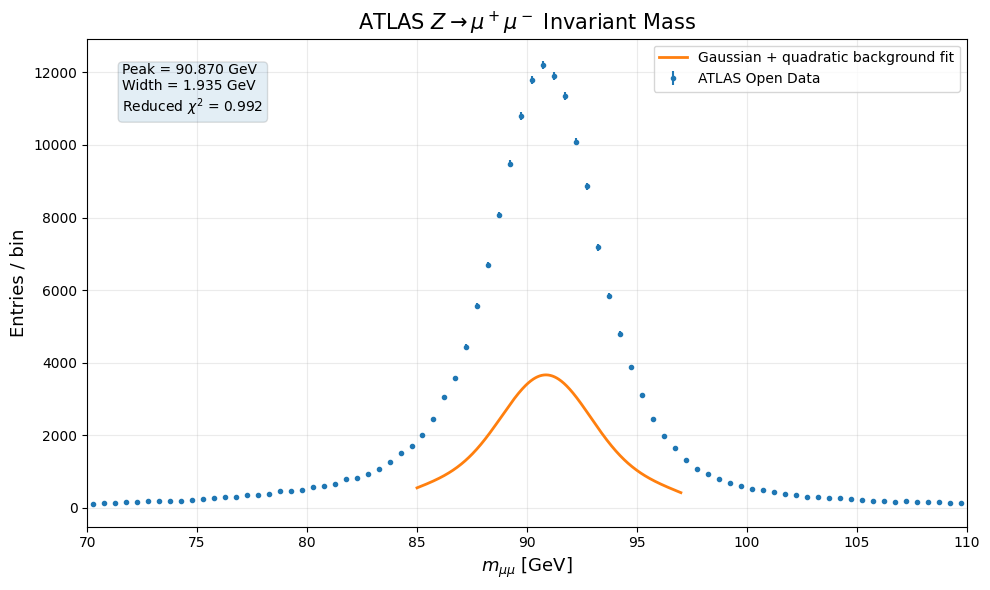

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# Final nominal selection and fit
# pT threshold = 25 GeV
# Fit range = 85–97 GeV
# Background model = quadratic

# Histogram of the reconstructed dimuon invariant mass
hist_range = (70, 110)
bins = 80

counts, edges = np.histogram(
    mass_values,
    bins=bins,
    range=hist_range
)

centers = (edges[:-1] + edges[1:]) / 2
bin_width = edges[1] - edges[0]

# Statistical uncertainties
errors = np.sqrt(counts)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    centers,
    counts,
    yerr=errors,
    fmt="o",
    markersize=3,
    capsize=0,
    label="ATLAS Open Data"
)

# Use the quadratic fit parameters from the 85–97 GeV fit
fit_x = np.linspace(85, 97, 500)

fit_y = gaussian_quadratic_centered(
    fit_x,
    *parameters
)

ax.plot(
    fit_x,
    fit_y,
    linewidth=2,
    label="Gaussian + quadratic background fit"
)

ax.set_xlabel(r"$m_{\mu\mu}$ [GeV]", fontsize=13)
ax.set_ylabel("Entries / bin", fontsize=13)

ax.set_title(
    r"ATLAS $Z\rightarrow\mu^+\mu^-$ Invariant Mass",
    fontsize=15
)

ax.set_xlim(hist_range)
ax.grid(alpha=0.25)
ax.legend()

# Add fit information
ax.text(
    0.04,
    0.95,
    f"Peak = {peak:.3f} GeV\n"
    f"Width = {abs(width):.3f} GeV\n"
    f"Reduced $\\chi^2$ = {reduced_chi_squared:.3f}",
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", alpha=0.12)
)

plt.tight_layout()
plt.show()

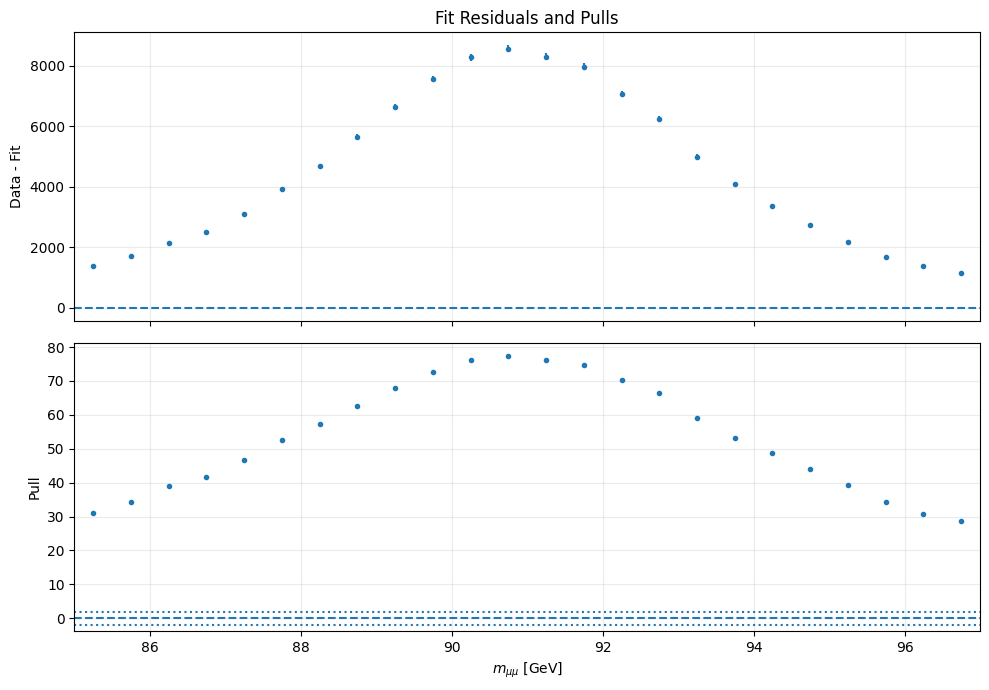

Mean pull: 53.54003693875117
Pull standard deviation: 16.155175974849634
Maximum absolute pull: 77.40399651056327


In [39]:
# Final fit diagnostics: residuals and pulls

# Use the same fit range and histogram as the nominal fit
fit_mask = (centers >= 85) & (centers <= 97)

fit_centers = centers[fit_mask]
observed = counts[fit_mask]
observed_errors = np.sqrt(np.maximum(observed, 1))

expected = gaussian_quadratic_centered(
    fit_centers,
    *parameters
)

# Residuals and pulls
residuals = observed - expected
pulls = residuals / observed_errors

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1]}
)

# Residual panel
axes[0].errorbar(
    fit_centers,
    residuals,
    yerr=observed_errors,
    fmt="o",
    markersize=3
)

axes[0].axhline(0, linestyle="--")
axes[0].set_ylabel("Data - Fit")
axes[0].set_title("Fit Residuals and Pulls")
axes[0].grid(alpha=0.25)

# Pull panel
axes[1].plot(
    fit_centers,
    pulls,
    "o",
    markersize=3
)

axes[1].axhline(0, linestyle="--")
axes[1].axhline(2, linestyle=":")
axes[1].axhline(-2, linestyle=":")

axes[1].set_xlabel(r"$m_{\mu\mu}$ [GeV]")
axes[1].set_ylabel("Pull")
axes[1].grid(alpha=0.25)

axes[1].set_xlim(85, 97)

plt.tight_layout()
plt.show()

print("Mean pull:", np.mean(pulls))
print("Pull standard deviation:", np.std(pulls))
print("Maximum absolute pull:", np.max(np.abs(pulls)))

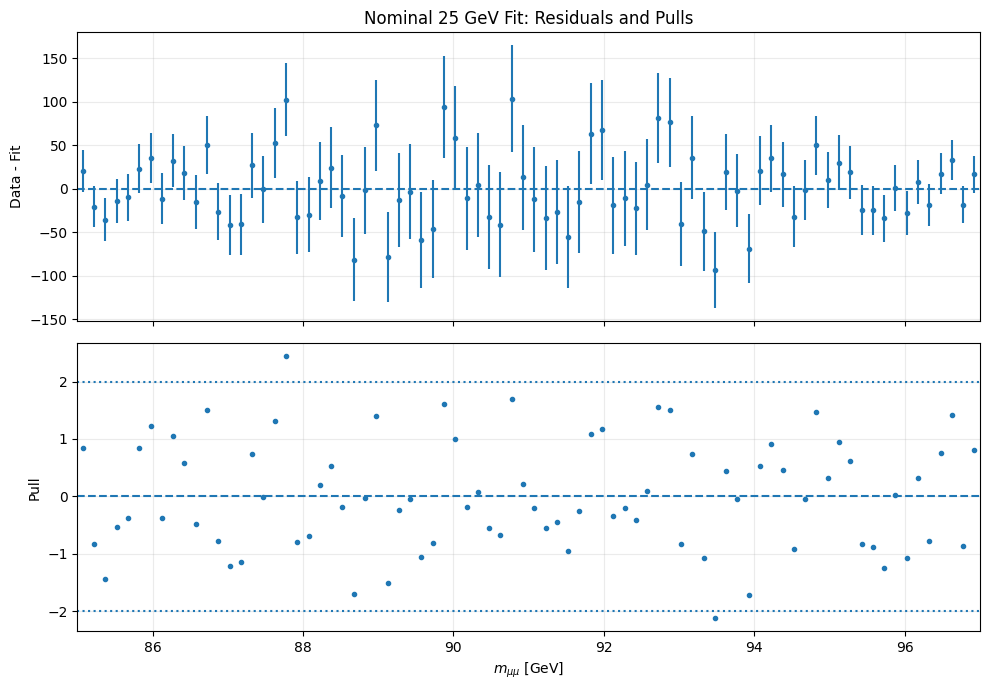

Nominal peak: 90.870210 GeV
Peak uncertainty: 0.012148 GeV
Gaussian width: 1.935046 GeV
Reduced chi-square: 0.992469
Mean pull: 0.011707
Pull standard deviation: 0.958069
Maximum absolute pull: 2.442285


In [40]:
# Rebuild the nominal 25 GeV fit and its diagnostics consistently

from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

# Nominal sample: 25 GeV threshold
# Fit range: 85–97 GeV
# Number of bins: 80

fit_counts, fit_edges = np.histogram(
    mass_values,
    bins=80,
    range=(85, 97)
)

fit_centers = (fit_edges[:-1] + fit_edges[1:]) / 2
fit_errors = np.sqrt(np.maximum(fit_counts, 1))

# Refit the nominal sample
initial_guess = [
    fit_counts.max(),
    90.8,
    2.0,
    0.0,
    0.0,
    fit_counts.min()
]

nominal_parameters, nominal_covariance = curve_fit(
    gaussian_quadratic_centered,
    fit_centers,
    fit_counts,
    p0=initial_guess,
    sigma=fit_errors,
    absolute_sigma=True,
    maxfev=20000
)

# Expected counts from the same fitted histogram
nominal_expected = gaussian_quadratic_centered(
    fit_centers,
    *nominal_parameters
)

# Calculate residuals and pulls
nominal_residuals = fit_counts - nominal_expected
nominal_pulls = nominal_residuals / fit_errors

# Fit quality
nominal_chi_squared = np.sum(nominal_pulls**2)
nominal_dof = len(fit_counts) - len(nominal_parameters)
nominal_reduced_chi_squared = nominal_chi_squared / nominal_dof

# Pull diagnostic plot
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True
)

axes[0].errorbar(
    fit_centers,
    nominal_residuals,
    yerr=fit_errors,
    fmt="o",
    markersize=3
)
axes[0].axhline(0, linestyle="--")
axes[0].set_ylabel("Data - Fit")
axes[0].set_title("Nominal 25 GeV Fit: Residuals and Pulls")
axes[0].grid(alpha=0.25)

axes[1].plot(
    fit_centers,
    nominal_pulls,
    "o",
    markersize=3
)
axes[1].axhline(0, linestyle="--")
axes[1].axhline(2, linestyle=":")
axes[1].axhline(-2, linestyle=":")
axes[1].set_xlabel(r"$m_{\mu\mu}$ [GeV]")
axes[1].set_ylabel("Pull")
axes[1].set_xlim(85, 97)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Print the correct nominal fit results
nominal_peak = nominal_parameters[1]
nominal_peak_uncertainty = np.sqrt(nominal_covariance[1, 1])
nominal_width = abs(nominal_parameters[2])

print(f"Nominal peak: {nominal_peak:.6f} GeV")
print(f"Peak uncertainty: {nominal_peak_uncertainty:.6f} GeV")
print(f"Gaussian width: {nominal_width:.6f} GeV")
print(f"Reduced chi-square: {nominal_reduced_chi_squared:.6f}")
print(f"Mean pull: {np.mean(nominal_pulls):.6f}")
print(f"Pull standard deviation: {np.std(nominal_pulls):.6f}")
print(f"Maximum absolute pull: {np.max(np.abs(nominal_pulls)):.6f}")

In [41]:
# Reconstruct the nominal 25 GeV sample independently
# This avoids using mass_values left over from the robustness loop.

muons_25 = selected_muons[
    selected_muons["pt"] > 25_000
]

muons_25 = muons_25[
    ak.num(muons_25["pt"], axis=1) >= 2
]

pairs_25 = ak.combinations(
    muons_25, 2, fields=["mu1", "mu2"]
)

pairs_25_os = pairs_25[
    pairs_25["mu1"]["charge"] * pairs_25["mu2"]["charge"] < 0
]

px1 = pairs_25_os["mu1"]["pt"] * np.cos(pairs_25_os["mu1"]["phi"])
py1 = pairs_25_os["mu1"]["pt"] * np.sin(pairs_25_os["mu1"]["phi"])
pz1 = pairs_25_os["mu1"]["pt"] * np.sinh(pairs_25_os["mu1"]["eta"])

px2 = pairs_25_os["mu2"]["pt"] * np.cos(pairs_25_os["mu2"]["phi"])
py2 = pairs_25_os["mu2"]["pt"] * np.sin(pairs_25_os["mu2"]["phi"])
pz2 = pairs_25_os["mu2"]["pt"] * np.sinh(pairs_25_os["mu2"]["eta"])

E1 = pairs_25_os["mu1"]["E"]
E2 = pairs_25_os["mu2"]["E"]

m2_25 = (
    (E1 + E2)**2
    - (px1 + px2)**2
    - (py1 + py2)**2
    - (pz1 + pz2)**2
)

nominal_mass_values = np.sqrt(
    ak.to_numpy(
        ak.flatten(
            ak.where(m2_25 > 0, m2_25, 0)
        )
    )
) / 1000

print("25 GeV opposite-charge pair entries:", len(nominal_mass_values))
print("25 GeV mass array reconstructed.")

25 GeV opposite-charge pair entries: 226483
25 GeV mass array reconstructed.


In [42]:
# Final nominal fit: 25 GeV pT threshold
# Fit window: 85–97 GeV
# Background: quadratic

nominal_counts, nominal_edges = np.histogram(
    nominal_mass_values,
    bins=80,
    range=(85, 97)
)

nominal_centers = (nominal_edges[:-1] + nominal_edges[1:]) / 2
nominal_errors = np.sqrt(np.maximum(nominal_counts, 1))

nominal_initial_guess = [
    nominal_counts.max(),
    90.8,
    2.0,
    0.0,
    0.0,
    nominal_counts.min()
]

nominal_parameters, nominal_covariance = curve_fit(
    gaussian_quadratic_centered,
    nominal_centers,
    nominal_counts,
    p0=nominal_initial_guess,
    sigma=nominal_errors,
    absolute_sigma=True,
    maxfev=20000
)

nominal_expected = gaussian_quadratic_centered(
    nominal_centers,
    *nominal_parameters
)

nominal_pulls = (
    nominal_counts - nominal_expected
) / nominal_errors

nominal_chi_squared = np.sum(nominal_pulls**2)
nominal_dof = len(nominal_counts) - len(nominal_parameters)
nominal_reduced_chi_squared = nominal_chi_squared / nominal_dof

nominal_peak = nominal_parameters[1]
nominal_peak_uncertainty = np.sqrt(nominal_covariance[1, 1])
nominal_width = abs(nominal_parameters[2])

print(f"Nominal pT threshold: 25 GeV")
print(f"Pair entries: {len(nominal_mass_values)}")
print(f"Fitted peak: {nominal_peak:.6f} GeV")
print(f"Peak uncertainty: {nominal_peak_uncertainty:.6f} GeV")
print(f"Gaussian width: {nominal_width:.6f} GeV")
print(f"Reduced chi-square: {nominal_reduced_chi_squared:.6f}")
print(f"Mean pull: {np.mean(nominal_pulls):.6f}")
print(f"Pull standard deviation: {np.std(nominal_pulls):.6f}")
print(f"Maximum absolute pull: {np.max(np.abs(nominal_pulls)):.6f}")

Nominal pT threshold: 25 GeV
Pair entries: 226483
Fitted peak: 90.829451 GeV
Peak uncertainty: 0.011130 GeV
Gaussian width: 1.933277 GeV
Reduced chi-square: 1.126847
Mean pull: 0.011890
Pull standard deviation: 1.020878
Maximum absolute pull: 2.441927


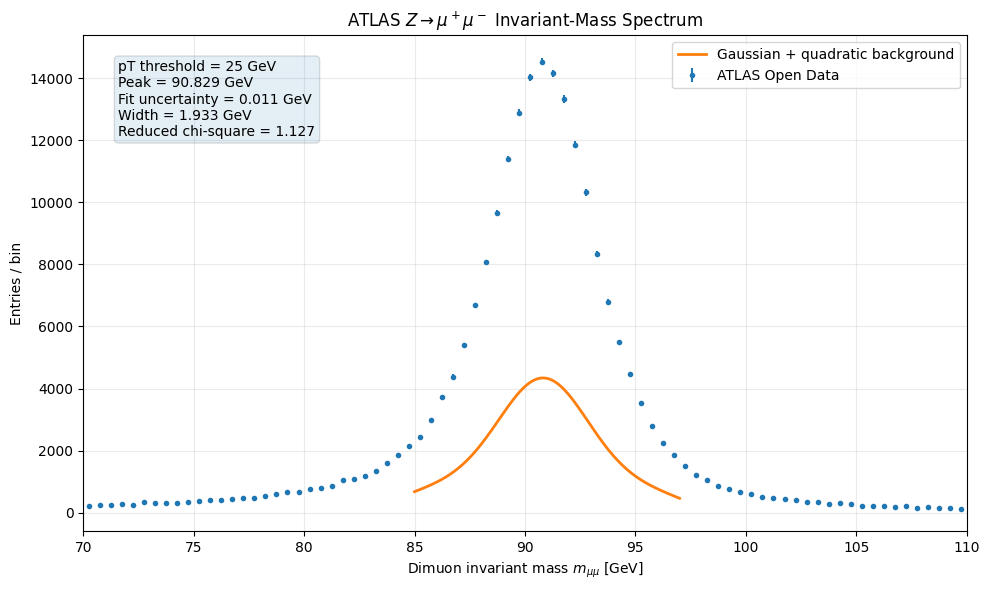

Saved: atlas_z_dimuon_mass_spectrum.png


In [43]:
# Final nominal invariant-mass spectrum
# Uses the confirmed 25 GeV sample and fit

import matplotlib.pyplot as plt
import numpy as np

# Histogram over the wider mass range
plot_counts, plot_edges = np.histogram(
    nominal_mass_values,
    bins=80,
    range=(70, 110)
)

plot_centers = (plot_edges[:-1] + plot_edges[1:]) / 2
plot_errors = np.sqrt(plot_counts)

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    plot_centers,
    plot_counts,
    yerr=plot_errors,
    fmt="o",
    markersize=3,
    label="ATLAS Open Data"
)

# Nominal fit curve, evaluated only in the fit window
fit_x = np.linspace(85, 97, 500)

fit_y = gaussian_quadratic_centered(
    fit_x,
    *nominal_parameters
)

ax.plot(
    fit_x,
    fit_y,
    linewidth=2,
    label="Gaussian + quadratic background"
)

ax.set_xlabel(r"Dimuon invariant mass $m_{\mu\mu}$ [GeV]")
ax.set_ylabel("Entries / bin")
ax.set_title(r"ATLAS $Z\rightarrow\mu^+\mu^-$ Invariant-Mass Spectrum")

ax.set_xlim(70, 110)
ax.grid(alpha=0.25)
ax.legend()

ax.text(
    0.04,
    0.95,
    f"pT threshold = 25 GeV\n"
    f"Peak = {nominal_peak:.3f} GeV\n"
    f"Fit uncertainty = {nominal_peak_uncertainty:.3f} GeV\n"
    f"Width = {nominal_width:.3f} GeV\n"
    f"Reduced chi-square = {nominal_reduced_chi_squared:.3f}",
    transform=ax.transAxes,
    va="top",
    bbox=dict(boxstyle="round", alpha=0.12)
)

plt.tight_layout()

fig.savefig(
    "atlas_z_dimuon_mass_spectrum.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: atlas_z_dimuon_mass_spectrum.png")

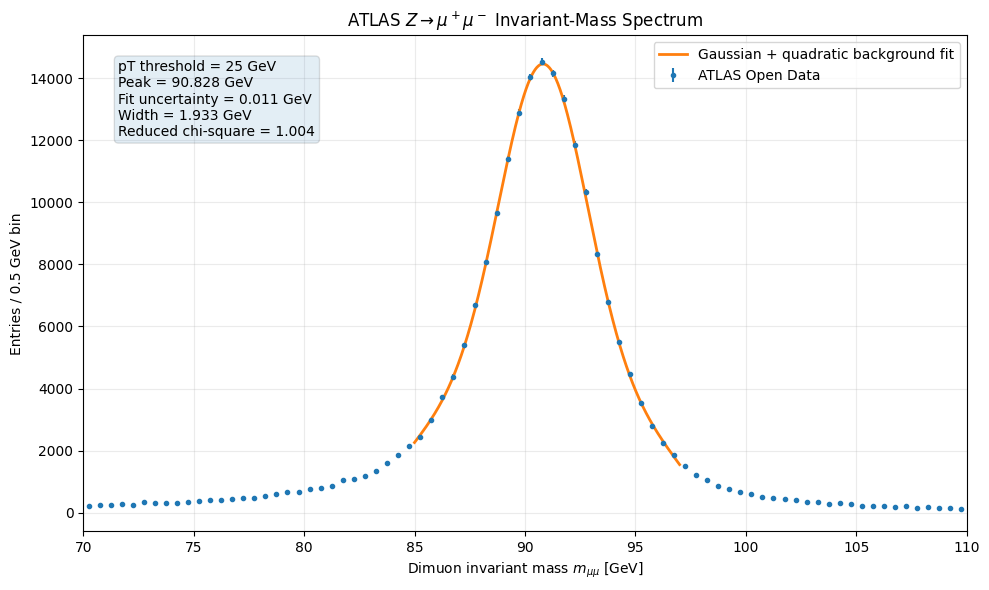

Final fitted peak: 90.828248 GeV
Fit uncertainty: 0.011227 GeV
Gaussian width: 1.933044 GeV
Reduced chi-square: 1.004412
Mean pull: 0.004350
Pull standard deviation: 0.867923
Maximum absolute pull: 1.794683


In [44]:
# Correct final spectrum:
# Same binning for histogram, fit, and plotted model

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# One histogram across the displayed range
plot_counts, plot_edges = np.histogram(
    nominal_mass_values,
    bins=80,
    range=(70, 110)
)

plot_centers = (plot_edges[:-1] + plot_edges[1:]) / 2
plot_errors = np.sqrt(np.maximum(plot_counts, 1))

# Select fit bins within 85–97 GeV
fit_mask = (plot_centers >= 85) & (plot_centers <= 97)

fit_centers_final = plot_centers[fit_mask]
fit_counts_final = plot_counts[fit_mask]
fit_errors_final = plot_errors[fit_mask]

# Fit using the same 0.5 GeV bin width as the displayed histogram
initial_guess_final = [
    fit_counts_final.max(),
    90.8,
    2.0,
    0.0,
    0.0,
    fit_counts_final.min()
]

final_parameters, final_covariance = curve_fit(
    gaussian_quadratic_centered,
    fit_centers_final,
    fit_counts_final,
    p0=initial_guess_final,
    sigma=fit_errors_final,
    absolute_sigma=True,
    maxfev=20000
)

# Fit diagnostics
final_expected = gaussian_quadratic_centered(
    fit_centers_final,
    *final_parameters
)

final_pulls = (
    fit_counts_final - final_expected
) / fit_errors_final

final_chi_squared = np.sum(final_pulls**2)
final_dof = len(fit_counts_final) - len(final_parameters)
final_reduced_chi_squared = final_chi_squared / final_dof

final_peak = final_parameters[1]
final_peak_uncertainty = np.sqrt(final_covariance[1, 1])
final_width = abs(final_parameters[2])

# Draw final spectrum
fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    plot_centers,
    plot_counts,
    yerr=plot_errors,
    fmt="o",
    markersize=3,
    label="ATLAS Open Data"
)

fit_x_final = np.linspace(85, 97, 500)

fit_y_final = gaussian_quadratic_centered(
    fit_x_final,
    *final_parameters
)

ax.plot(
    fit_x_final,
    fit_y_final,
    linewidth=2,
    label="Gaussian + quadratic background fit"
)

ax.set_xlabel(r"Dimuon invariant mass $m_{\mu\mu}$ [GeV]")
ax.set_ylabel("Entries / 0.5 GeV bin")
ax.set_title(r"ATLAS $Z\rightarrow\mu^+\mu^-$ Invariant-Mass Spectrum")
ax.set_xlim(70, 110)
ax.grid(alpha=0.25)
ax.legend()

ax.text(
    0.04,
    0.95,
    f"pT threshold = 25 GeV\n"
    f"Peak = {final_peak:.3f} GeV\n"
    f"Fit uncertainty = {final_peak_uncertainty:.3f} GeV\n"
    f"Width = {final_width:.3f} GeV\n"
    f"Reduced chi-square = {final_reduced_chi_squared:.3f}",
    transform=ax.transAxes,
    va="top",
    bbox=dict(boxstyle="round", alpha=0.12)
)

plt.tight_layout()

fig.savefig(
    "atlas_z_dimuon_mass_spectrum.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Final fitted peak: {final_peak:.6f} GeV")
print(f"Fit uncertainty: {final_peak_uncertainty:.6f} GeV")
print(f"Gaussian width: {final_width:.6f} GeV")
print(f"Reduced chi-square: {final_reduced_chi_squared:.6f}")
print(f"Mean pull: {np.mean(final_pulls):.6f}")
print(f"Pull standard deviation: {np.std(final_pulls):.6f}")
print(f"Maximum absolute pull: {np.max(np.abs(final_pulls)):.6f}")

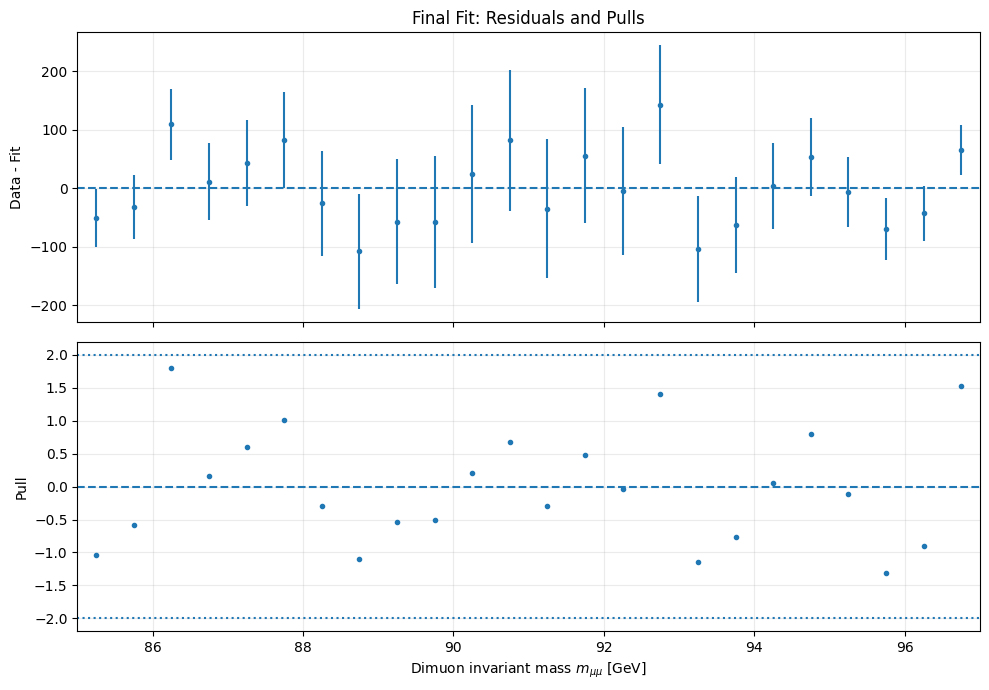

Saved final residual and pull figure.


In [45]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True
)

# Residuals from the final consistent fit
final_residuals = fit_counts_final - final_expected

axes[0].errorbar(
    fit_centers_final,
    final_residuals,
    yerr=fit_errors_final,
    fmt="o",
    markersize=3
)

axes[0].axhline(0, linestyle="--")
axes[0].set_ylabel("Data - Fit")
axes[0].set_title("Final Fit: Residuals and Pulls")
axes[0].grid(alpha=0.25)

# Pulls
axes[1].plot(
    fit_centers_final,
    final_pulls,
    "o",
    markersize=3
)

axes[1].axhline(0, linestyle="--")
axes[1].axhline(2, linestyle=":")
axes[1].axhline(-2, linestyle=":")

axes[1].set_xlabel(r"Dimuon invariant mass $m_{\mu\mu}$ [GeV]")
axes[1].set_ylabel("Pull")
axes[1].set_xlim(85, 97)
axes[1].grid(alpha=0.25)

plt.tight_layout()

fig.savefig(
    "atlas_z_fit_residuals_pulls.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved final residual and pull figure.")